# SubTSMD example

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from tsmd.competitors.locomotif import LocoMotif
from tsmd.competitors.matrixprofile import MatrixProfile
from tsmd.competitors.subtsmd import SubTSMD
from tsmd.competitors.persistence import BasePersistentPattern

## The time series

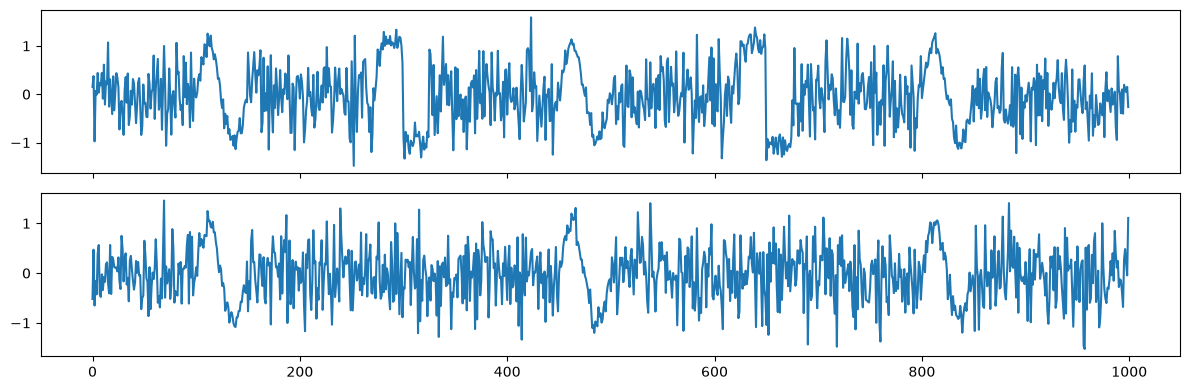

In [2]:
rng = np.random.default_rng(42)
n, wlen = 1000, 50
t = np.linspace(0, 1, wlen)

X = rng.normal(scale=0.5, size=(n, 2))
for start in (100, 450, 800):  # Sine in both attributes
    X[start:start + wlen, 0] = np.sin(2 * np.pi * t) + rng.normal(scale=0.15, size=wlen)
    X[start:start + wlen, 1] = np.sin(2 * np.pi * t) + rng.normal(scale=0.15, size=wlen)
for start in (275, 625):  # Square pulse only in attribute 0
    X[start:start + wlen, 0] = np.where(t < 0.5, 1.0, -1.0) + rng.normal(scale=0.15, size=wlen)

fig, axs = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
for a, ax in enumerate(axs):
    ax.plot(X[:, a])
plt.tight_layout()

## Plotting the subspace motifs

In [3]:
def plot_subspace_motifs(X, model, title):
    fig, axs = plt.subplots(X.shape[1], 1, figsize=(12, 4), sharex=True)
    for a, ax in enumerate(axs):
        ax.plot(X[:, a])
    for i, (subspace, locations) in enumerate(model.motif_sets_):
        for j, attribute in enumerate(np.where(subspace)[0]):
            for start, end in locations[:, :, j]:
                axs[attribute].axvspan(start, end, color=f'C{i}', alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## Applying SubTSMD

>> SubTSMD + MatrixProfile
prediction_mask_: (5, 1000)
subspaces_: [[1, 1], [1, 1], [1, 0], [1, 0], [0, 1]]
motif set 0: attributes [0, 1], occurrences [(98, 148), (449, 499), (799, 849)]
motif set 1: attributes [0, 1], occurrences [(164, 214), (324, 374), (376, 426), (741, 791), (849, 899)]
motif set 2: attributes [0], occurrences [(274, 324), (624, 674)]
motif set 3: attributes [0], occurrences [(31, 81), (215, 265), (531, 581), (685, 735), (912, 962)]
motif set 4: attributes [1], occurrences [(2, 52), (240, 290), (507, 557), (570, 620), (640, 690), (947, 997)]


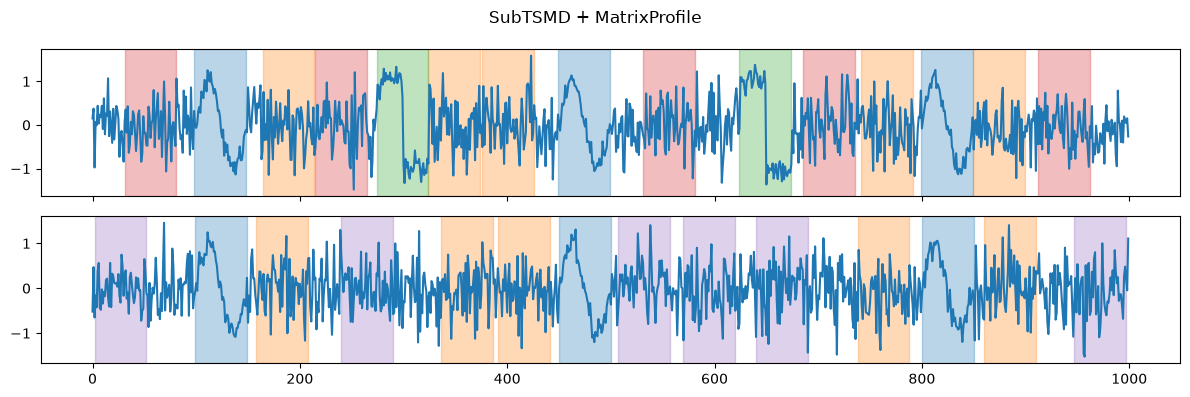

>> SubTSMD + LocoMotif
prediction_mask_: (3, 1000)
subspaces_: [[1, 1], [1, 0], [0, 1]]
motif set 0: attributes [0, 1], occurrences [(89, 149), (438, 501), (788, 849)]
motif set 1: attributes [0], occurrences [(3, 47), (178, 226), (737, 776)]
motif set 2: attributes [1], occurrences [(518, 561), (876, 921)]


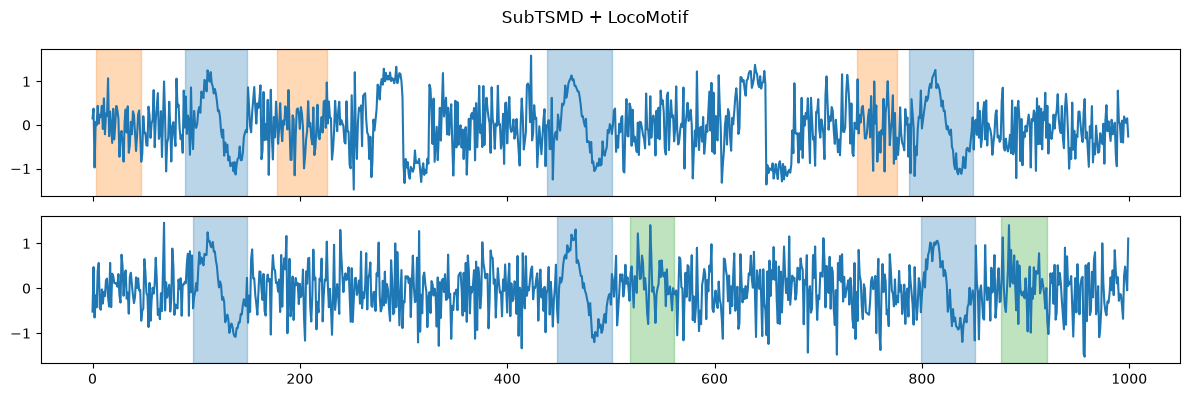

>> SubTSMD + BasePersistentPattern
prediction_mask_: (2, 1000)
subspaces_: [[1, 1], [1, 0]]
motif set 0: attributes [0, 1], occurrences [(95, 140), (444, 491)]
motif set 1: attributes [0], occurrences [(272, 312), (622, 662)]


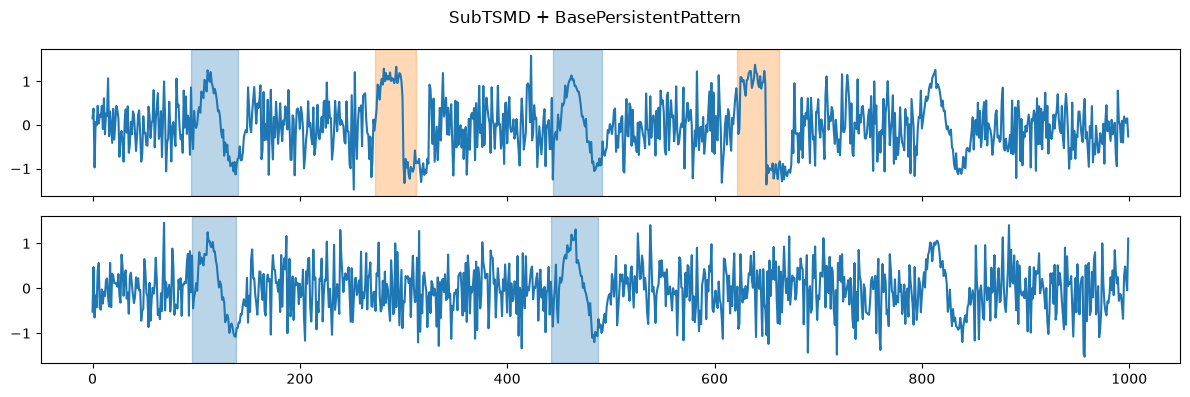

In [4]:
methods = [
    MatrixProfile(n_patterns=2, wlen=50, distance_name="NormalizedEuclidean"),
    LocoMotif(min_wlen=40, max_wlen=60, n_patterns=2),
    BasePersistentPattern(n_patterns=2, wlen_for_persistence=40),
]

for method in methods:
    model = SubTSMD(method).fit(X)
    print(f">> SubTSMD + {method.__class__.__name__}")
    print("prediction_mask_:", model.prediction_mask_.shape)
    print("subspaces_:", model.subspaces_.astype(int).tolist())
    for i, (subspace, locations) in enumerate(model.motif_sets_):
        occurrences = [(int(s), int(e)) for s, e in locations[:, :, 0]]
        print(f"motif set {i}: attributes {np.where(subspace)[0].tolist()}, occurrences {occurrences}")
    plot_subspace_motifs(X, model, f"SubTSMD + {method.__class__.__name__}")